In [1]:
%load_ext rpy2.ipython

/Users/arturohernanzcarrasco-munoz/code/analisis_datos_clasificacion/.venv/lib/python3.9/site-packages/rpy2/ipython/rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [2]:
%%R
lib_loc <- "lib_loc_100"

In [3]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [4]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))

if (!require("psych", lib.loc = lib_loc)) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr", lib.loc = lib_loc)) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc", lib.loc = lib_loc)) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("dplyr", lib.loc = lib_loc)) install.packages("dplyr", lib = lib_loc)
library(dplyr, lib.loc = lib_loc)
if (!require("GGally", lib.loc = lib_loc)) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot", lib.loc = lib_loc)) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)
if (!require("survey", lib.loc = lib_loc)) install.packages("survey", lib = lib_loc)
library(survey, lib.loc = lib_loc)
if (!require("mitools", lib.loc = lib_loc)) install.packages("mitools", lib = lib_loc)
library(mitools, lib.loc = lib_loc)
if (!require("relaimpo", lib.loc = lib_loc)) install.packages("relaimpo", lib = lib_loc)
library(relaimpo, lib.loc = lib_loc)
if (!require("FSelectorRcpp", lib.loc = lib_loc)) install.packages("FSelectorRcpp", lib = lib_loc)
library(FSelectorRcpp, lib.loc = lib_loc)
if (!require("ranger", lib.loc = lib_loc)) install.packages("ranger", lib = lib_loc)
library(ranger, lib.loc = lib_loc)
if (!require("Boruta", lib.loc = lib_loc)) install.packages("Boruta", lib = lib_loc)
library(Boruta, lib.loc = lib_loc)
if (!require("randomForest", lib.loc = lib_loc)) install.packages("randomForest", lib = lib_loc)
library(randomForest, lib.loc = lib_loc)
if (!require("caret", lib.loc = lib_loc)) install.packages("caret", lib = lib_loc)
library(caret, lib.loc = lib_loc)
if (!require("e1071", lib.loc = lib_loc)) install.packages("e1071", lib = lib_loc)
library(e1071, lib.loc = lib_loc)

if (!require("ggsci", lib.loc = lib_loc)) install.packages("ggsci", lib = lib_loc)
library(ggsci, lib.loc = lib_loc)
if (!require("dendextend", lib.loc = lib_loc)) install.packages("dendextend", lib = lib_loc)
library(dendextend, lib.loc = lib_loc)
if (!require("factoextra", lib.loc = lib_loc)) install.packages("factoextra", lib = lib_loc)
library(factoextra, lib.loc = lib_loc)
if (!require("FactoMineR", lib.loc = lib_loc)) install.packages("FactoMineR", lib = lib_loc)
library(FactoMineR, lib.loc = lib_loc)
if (!require("nFactors", lib.loc = lib_loc)) install.packages("nFactors", lib = lib_loc)
library(nFactors, lib.loc = lib_loc)


if(os=="Darwin"){
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps_3.2.tgz", lib = lib_loc, repos = NULL, type = "mac.binary")
    library(leaps, lib.loc = lib_loc)
}else{
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps", lib = lib_loc)
    library(leaps, lib.loc = lib_loc)
}

Loading required package: psych
Loading required package: plyr
Loading required package: Rmisc
Loading required package: lattice
Loading required package: dplyr

Attaching package: ‘dplyr’

The following objects are masked from ‘package:plyr’:

    arrange, count, desc, failwith, id, mutate, rename, summarise,
    summarize

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

Loading required package: GGally
Loading required package: ggplot2

Attaching package: ‘ggplot2’

The following objects are masked from ‘package:psych’:

    %+%, alpha

Loading required package: corrplot
corrplot 0.95 loaded
Loading required package: survey
Loading required package: grid
Loading required package: Matrix
Loading required package: survival

Attaching package: ‘survey’

The following object is masked from ‘package:graphics’:

    dotchart

Loading required package: mitools
Loading req

# Carga del fichero

In [20]:
%%R

dfMedidas <- read.csv("apartment+for+rent+classified/apartments_for_rent_classified_100K.csv", 
                      sep = ";", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      na.strings = c("null", "NULL", "", " ", "NA", "None"),
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [6]:
%%R
head(dfMedidas, 5)

          id               category                           title
1 5668640009 housing/rent/apartment      One BR 507 & 509 Esplanade
2 5668639818 housing/rent/apartment     Three BR 146 Lochview Drive
3 5668639686 housing/rent/apartment Three BR 3101 Morningside Drive
4 5668639659 housing/rent/apartment           Two BR 209 Aegean Way
5 5668639374 housing/rent/apartment        One BR 4805 Marquette NE
                                                                                                                                                          body
1            This unit is located at 507 & 509 Esplanade, Redondo Beach, 90277, CAMonthly rental rates range from $2195We have 1 beds units available for rent
2              This unit is located at 146 Lochview Drive, Newport News, 23602, VAMonthly rental rates range from $1250We have 3 beds units available for rent
3               This unit is located at 3101 Morningside Drive, Raleigh, 27607, NCMonthly rental rates range from $

Analizamos los tipos de variables

In [7]:
%%R
str(dfMedidas)

'data.frame':	52746 obs. of  22 variables:
 $ id           : num  5.67e+09 5.67e+09 5.67e+09 5.67e+09 5.67e+09 ...
 $ category     : Factor w/ 6 levels "housing/rent",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ title        : Factor w/ 35113 levels ". Sierra. Unit A Reno, NV",..: 19257 28416 28677 30950 19188 31724 31468 30621 30767 30561 ...
 $ body         : Factor w/ 50995 levels " For those of you desiring a beautiful community without sacrificing convenience, The Fields Market is the perf"| __truncated__,..: 43339 40188 42081 41044 43199 44448 45209 39463 40151 39178 ...
 $ amenities    : Factor w/ 7397 levels " It is 1 of a kind- West side luxurious and amenities with East side rents. Residents can meet friends in the p"| __truncated__,..: NA NA NA NA NA NA NA NA NA NA ...
 $ bathrooms    : Factor w/ 21 levels "1","1.5","2",..: 1 2 3 1 1 2 3 3 1 3 ...
 $ bedrooms     : Factor w/ 11 levels "0","1","2","3",..: 2 4 4 3 2 3 3 3 3 3 ...
 $ currency     : Factor w/ 6 levels "1","2","3","5",..: 6 6 

# EDA

Como podemos ver todas las variables son categóricas, algo que no tiene sentido con variables como "price", "bathrooms" o "longitude", así que cambiamos los tipos de datos a los reales o que tienen sentido:

In [21]:
%%R
categoricas <- c(
  "category", "title", "body", "amenities", "currency",
  "has_photo", "pets_allowed", "price_display",
  "price_type", "cityname", "state", "source"
)

numericas <- c(
  "id", "bathrooms", "price",
  "latitude", "longitude", "square_feet"
)

ordinales <- c("time")


dfMedidas[categoricas] <- lapply(dfMedidas[categoricas], as.factor)

dfMedidas[numericas] <- lapply(dfMedidas[numericas], function(x) {
  as.numeric(as.character(x))
})

dfMedidas$time <- as.numeric(as.character(dfMedidas$time))
dfMedidas$latitude  <- as.numeric(as.character(dfMedidas$latitude))
dfMedidas$longitude <- as.numeric(as.character(dfMedidas$longitude))


In addition: Warning messages:
1: In FUN(X[[i]], ...) : NAs introduced by coercion
2: In FUN(X[[i]], ...) : NAs introduced by coercion
3: In FUN(X[[i]], ...) : NAs introduced by coercion
4: In FUN(X[[i]], ...) : NAs introduced by coercion
5: In FUN(X[[i]], ...) : NAs introduced by coercion
6: In (function (expr, envir = parent.frame(), enclos = if (is.list(envir) ||  :
  NAs introduced by coercion


In [22]:
%%R
str(dfMedidas)

'data.frame':	52746 obs. of  22 variables:
 $ id           : num  5.67e+09 5.67e+09 5.67e+09 5.67e+09 5.67e+09 ...
 $ category     : Factor w/ 6 levels "housing/rent",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ title        : Factor w/ 35113 levels ". Sierra. Unit A Reno, NV",..: 19257 28416 28677 30950 19188 31724 31468 30621 30767 30561 ...
 $ body         : Factor w/ 50995 levels " For those of you desiring a beautiful community without sacrificing convenience, The Fields Market is the perf"| __truncated__,..: 43339 40188 42081 41044 43199 44448 45209 39463 40151 39178 ...
 $ amenities    : Factor w/ 7397 levels " It is 1 of a kind- West side luxurious and amenities with East side rents. Residents can meet friends in the p"| __truncated__,..: NA NA NA NA NA NA NA NA NA NA ...
 $ bathrooms    : num  1 1.5 2 1 1 1.5 2 2 1 2 ...
 $ bedrooms     : Factor w/ 11 levels "0","1","2","3",..: 2 4 4 3 2 3 3 3 3 3 ...
 $ currency     : Factor w/ 6 levels "1","2","3","5",..: 6 6 6 6 6 6 6 6 6 6 ...
 $ fee   

Como podemos observar hay un total de 52746 instancias con 22 variables.
Estas variables se pueden dividir en categóricas, numéricas y una ordinal:

1)   Categóricas:
* category (Variable Objetivo): Categoría de la casa
* title: Título de la oferta
* body: Cuerpo de la oferta
* amenities: Comodidades
* currency: Moneda en la que está el precio
* has_photo: Tiene foto del apartamento o no
* pets_allowed: Permite o no mascotas (None, o lista con las opciones)
* price_display: Precio pero con el símbolo de la moneda en la que está
* price_type: Tipo de pago (Mensual, ...)
* cityname: Ciudad
* state: Estado
* source: Plataforma donde está la oferta


2)   Numéricas:
* id: Identificador de la casa
* bathrooms: Número de baños
* price: Precio de la casa (Número)
* latitude: Coordenada de latitud
* longitude: Coordenada de longitud
* address: Dirección
* fee: Señal (Número o "No")
* square_feet: Metros cuadrados

3) Ordinales:
* time: Tiempo desde que se creó la oferta


Cabe destacar que muchos de los valores numéricos no son de tipo entero, por lo que habrá que tratar los datos antes de tratar con ellos.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [10]:
%%R
describe(dfMedidas)

               vars     n          mean           sd        median
id                1 52746 5386522712.06 196424638.35 5508770378.50
category*         2 52739          2.00         0.04          2.00
title*            3 52739      16996.47     10242.31      16399.00
body*             4 52738      25447.47     14862.40      25334.50
amenities*        5 43034       5244.46      2224.16       6130.00
bathrooms         6 52681          1.43         0.55          1.00
bedrooms*         7 52679          2.73         0.78          3.00
currency*         8 52739          6.00         0.05          6.00
fee*              9 52739          1.01         0.17          1.00
has_photo*       10 52730          3.43         0.65          4.00
pets_allowed*    11 21516         14.95         0.36         15.00
price            12 52718       1523.55       898.94       1349.00
price_display*   13 52738       1282.40      1134.14        784.00
price_type*      14 52739         20.00         0.22         2

En este caso podemos ver que hay algunas columnas irrelevantes, ya sea por ser de id o que no aporten información como id; title; body; price_display; address, o amenities o por ser de valores constantes como fee y currency.

En cuanto a la cardinalidad máxima podemos ver que la variable con mayor rango es el nombre de la ciudad, alcanzndo los 1574 valores.

En cuanto a los valores faltantes, hay que tratar los datos para que se identifiquen los null como valores nulos

In [23]:
%%R 
data.frame(
  NAs = colSums(is.na(dfMedidas)),
  Perc = colSums(is.na(dfMedidas)) / nrow(dfMedidas) * 100
)

                NAs        Perc
id                0  0.00000000
category          7  0.01327115
title             7  0.01327115
body              8  0.01516703
amenities      9712 18.41277064
bathrooms        65  0.12323209
bedrooms         67  0.12702385
currency          7  0.01327115
fee               7  0.01327115
has_photo        16  0.03033405
pets_allowed  31230 59.20828120
price            28  0.05308459
price_display     8  0.01516703
price_type        7  0.01327115
square_feet      27  0.05118872
address       45480 86.22454783
cityname        182  0.34504986
state           175  0.33177871
latitude         27  0.05118872
longitude        33  0.06256399
source            7  0.01327115
time             27  0.05118872


In [24]:
%%R

dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("id", "title", "body", "price_display", "address", "amenities", "fee", "currency", "amenities", "pets_allowed")]

In [14]:
%%R
describe(dfMedidas)

            vars     n          mean          sd        median      trimmed
category*      1 52739          2.00        0.04          2.00  2.00000e+00
bathrooms      2 52681          1.43        0.55          1.00  1.38000e+00
bedrooms*      3 52679          2.73        0.78          3.00  2.64000e+00
has_photo*     4 52730          3.43        0.65          4.00  3.53000e+00
price          5 52718       1523.55      898.94       1349.00  1.40469e+03
price_type*    6 52739         20.00        0.22         20.00  2.00000e+01
square_feet    7 52719        953.10      387.11        897.00  9.13550e+02
cityname*      8 52564       1175.15      731.86       1159.50  1.15835e+03
state*         9 52571         40.71       17.09         43.00  4.06500e+01
latitude      10 52719         36.99        5.05         37.38  3.70700e+01
longitude     11 52713        -91.79       15.90        -85.69 -9.06000e+01
source*       12 52739         35.15        1.30         35.00  3.50800e+01
time        

In [25]:
%%R
str(dfMedidas)

'data.frame':	52746 obs. of  13 variables:
 $ category   : Factor w/ 6 levels "housing/rent",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ bathrooms  : num  1 1.5 2 1 1 1.5 2 2 1 2 ...
 $ bedrooms   : Factor w/ 11 levels "0","1","2","3",..: 2 4 4 3 2 3 3 3 3 3 ...
 $ has_photo  : Factor w/ 4 levels "Cats,Dogs","No",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ price      : num  2195 1250 1395 1600 975 ...
 $ price_type : Factor w/ 21 levels "$1,650","$1,800",..: 20 20 20 20 20 20 20 20 20 20 ...
 $ square_feet: num  542 1500 1650 820 624 ...
 $ cityname   : Factor w/ 2601 levels "Abbeville","Aberdeen",..: 1926 1603 1902 2362 19 19 951 1204 397 403 ...
 $ state      : Factor w/ 69 levels "32.8004","33.7435",..: 18 64 43 18 48 48 64 19 68 18 ...
 $ latitude   : num  33.9 37.1 35.8 38.4 35.1 ...
 $ longitude  : num  -118.4 -76.5 -78.6 -122 -106.6 ...
 $ source     : Factor w/ 42 levels "-104.8622","-70.7371",..: 37 37 37 37 37 37 37 37 37 37 ...
 $ time       : num  1.58e+09 1.58e+09 1.58e+09 1.58e+09 1.58e+09 ...


Analizamos cada variable con histogramas:

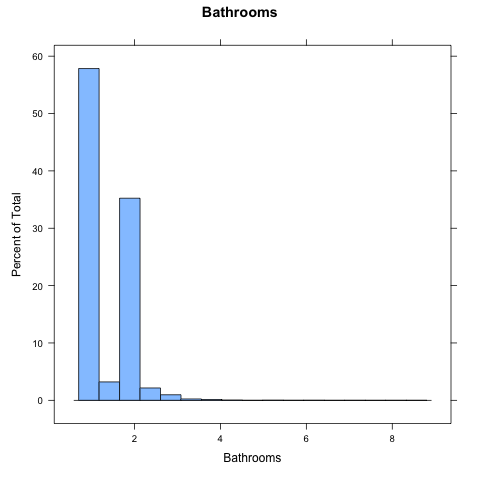

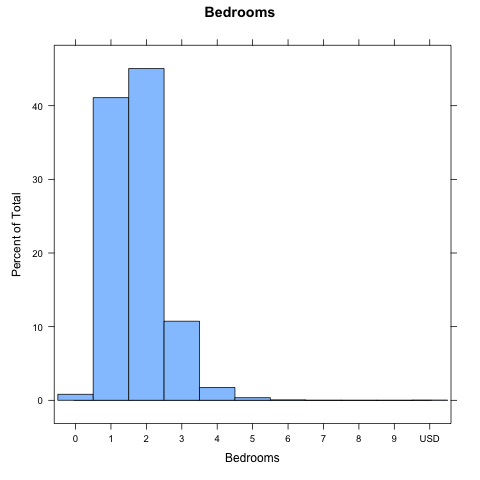

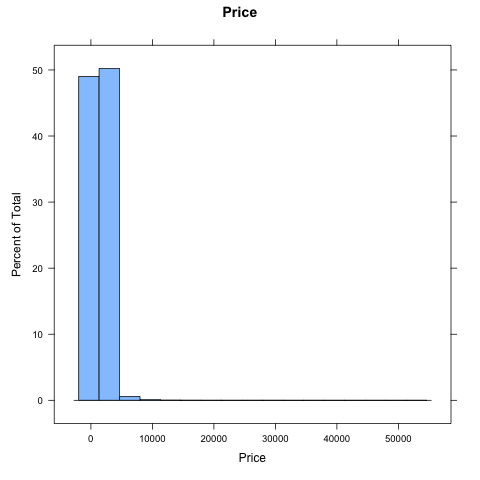

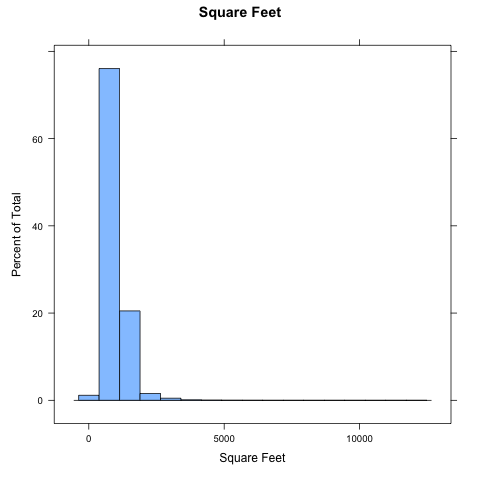

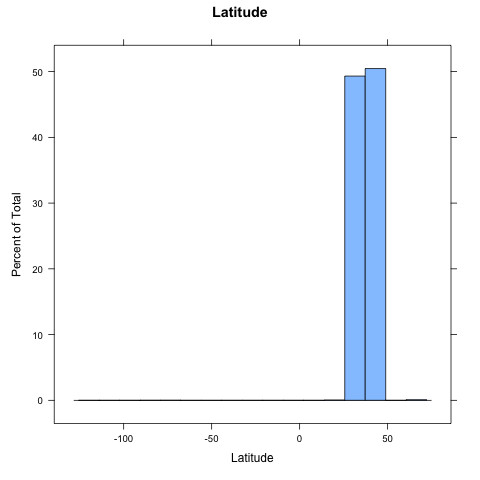

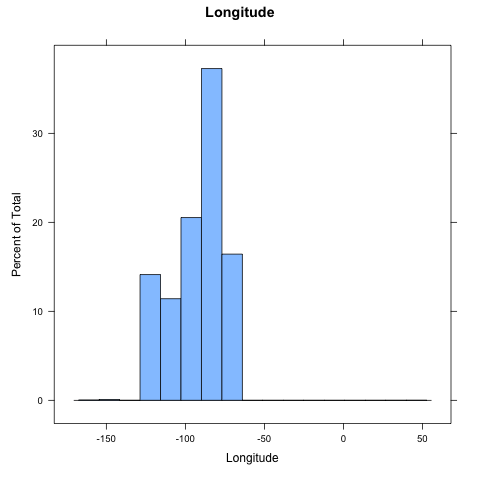

In [26]:
%%R

print(histogram(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms"))
print(histogram(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms"))
print(histogram(dfMedidas$price, main = "Price", xlab = "Price"))
print(histogram(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet"))
print(histogram(dfMedidas$latitude, main = "Latitude", xlab = "Latitude"))
print(histogram(dfMedidas$longitude, main = "Longitude", xlab = "Longitude"))

Podemos ver valores raros en el rango de latitud, por lo que hacemos una comporbación

In [28]:
%%R
print(summary(dfMedidas$latitude))
print(summary(dfMedidas$longitude))

print(range(dfMedidas$latitude, na.rm = TRUE))
print(range(dfMedidas$longitude, na.rm = TRUE))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
-118.28   33.75   37.38   36.99   40.05   64.83      27 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
-159.37 -104.77  -85.69  -91.79  -78.19   44.49      33 
[1] -118.2794   64.8332
[1] -159.3698   44.4872


Efectivamente, hay valores que no cumplen el rango real de latitud, por lo que hacemos los cambios oportunos.

In [29]:
%%R
dfMedidas$latitude[
  dfMedidas$latitude < -90 | dfMedidas$latitude > 90
] <- NA

dfMedidas$longitude[
  dfMedidas$longitude < -180 | dfMedidas$longitude > 180
] <- NA

In [ ]:
%%R
print(summary(dfMedidas$latitude))
print(summary(dfMedidas$longitude))

print(range(dfMedidas$latitude, na.rm = TRUE))
print(range(dfMedidas$longitude, na.rm = TRUE))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
 -85.52   33.75   37.38   37.00   40.05   64.83      29 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
-159.37 -104.77  -85.69  -91.79  -78.19   44.49      33 
[1] -85.5213  64.8332
[1] -159.3698   44.4872


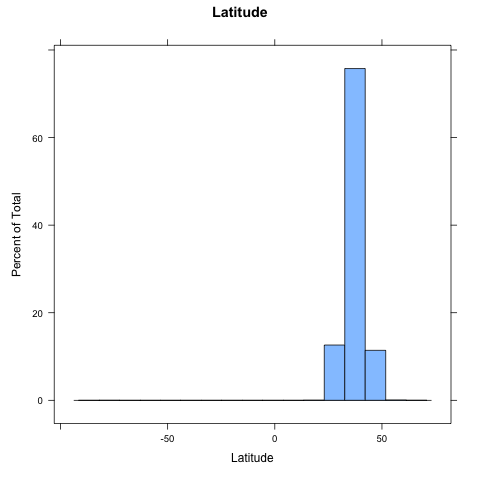

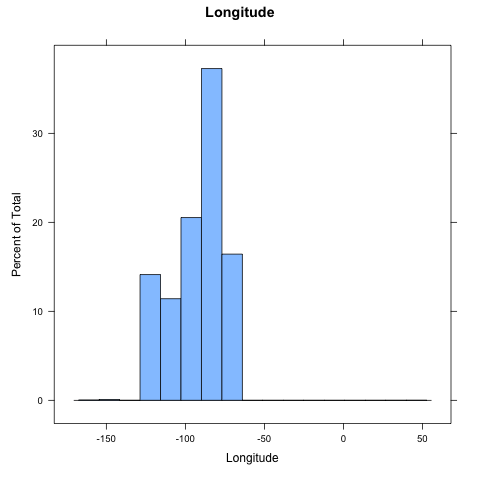

In [30]:
%%R
print(histogram(dfMedidas$latitude, main = "Latitude", xlab = "Latitude"))
print(histogram(dfMedidas$longitude, main = "Longitude", xlab = "Longitude"))

Podemos ver que todas las variables siguen una distribución normal, y podemos destacar la siguiente información:

* Podemos ver que la mayoría de precios está por debajo de los 10000 y los metros cuadrados tambien.
* Podemos ver que los valores de Longitud se concentran entere 60 y 130 aproximadamente, lo que tiene sentido dado que los Estados Unidos de América están comprendidos entre esas longitudes.
* En cuanto al número de habitaciones y baños podemos ver que, en general, no son muchos.

Evaluamos también la presencia de outliers con los diagramas de caja

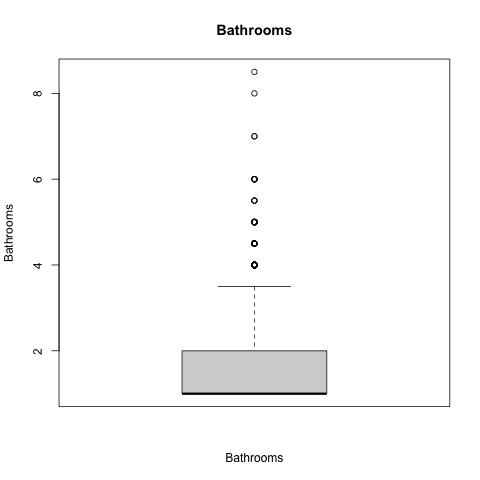

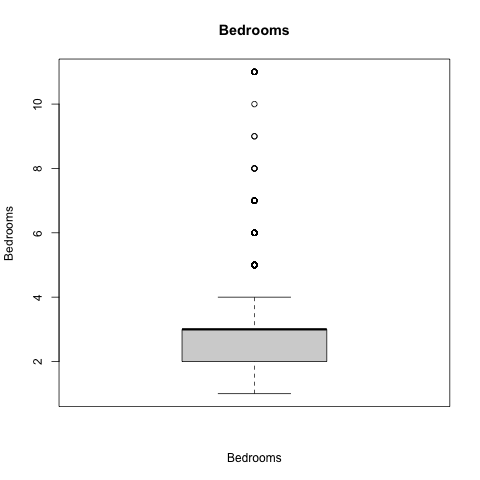

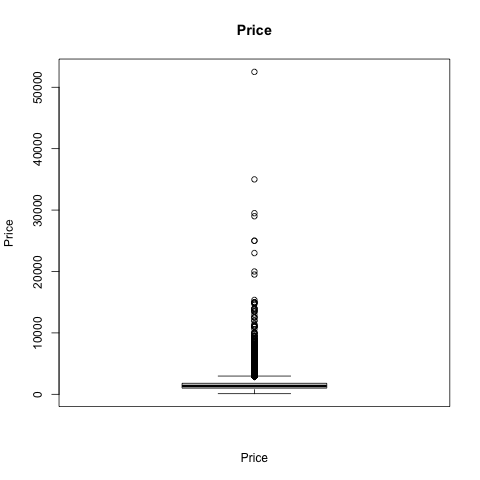

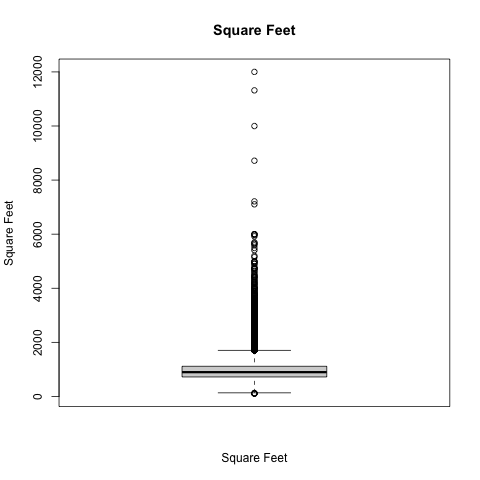

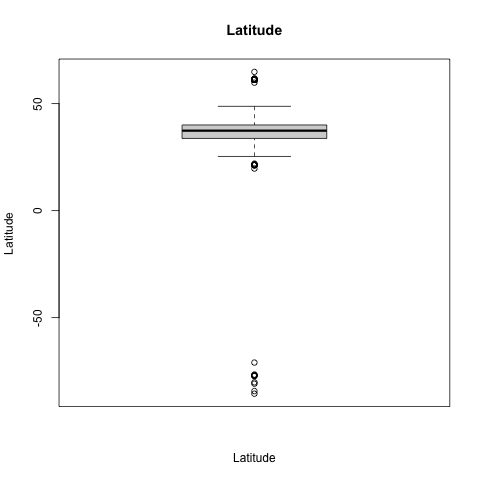

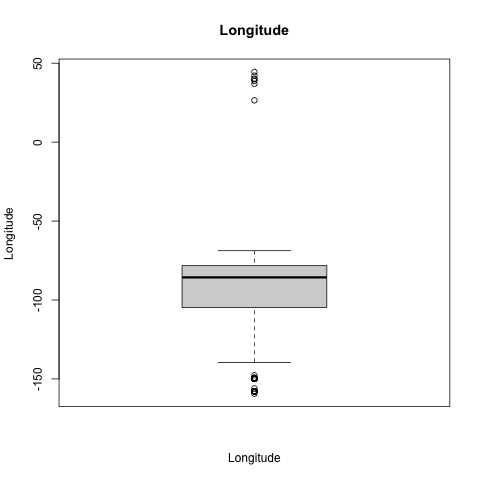

In [31]:
%%R
boxplot(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms", ylab = "Bathrooms")
boxplot(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms", ylab = "Bedrooms")
boxplot(dfMedidas$price, main = "Price", xlab = "Price", ylab = "Price")
boxplot(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet", ylab = "Square Feet")
boxplot(dfMedidas$latitude, main = "Latitude", xlab = "Latitude", ylab = "Latitude")
boxplot(dfMedidas$longitude, main = "Longitude", xlab = "Longitude", ylab = "Longitude")

Podemos ver que todas las variables presentan Outliers, siendo el precio y los metros cuadrados aquellas variables con más, por ello, y para buscar alguna explicación, observamos el impacto de la localización geográfica en estas variables y la objetivo.

In addition: Warning messages:
1: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 41 rows containing missing values or values outside the scale range
(`geom_point()`). 
3: Removed 41 rows containing missing values or values outside the scale range
(`geom_point()`). 


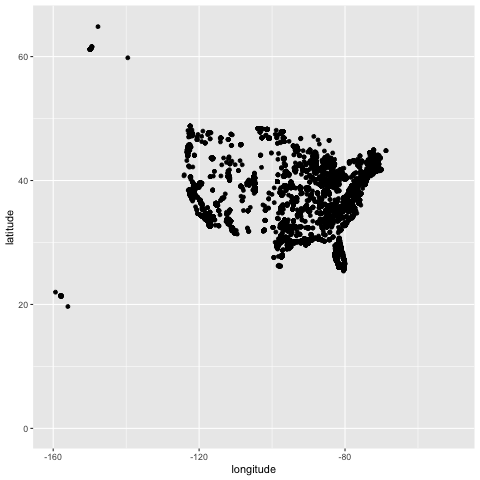

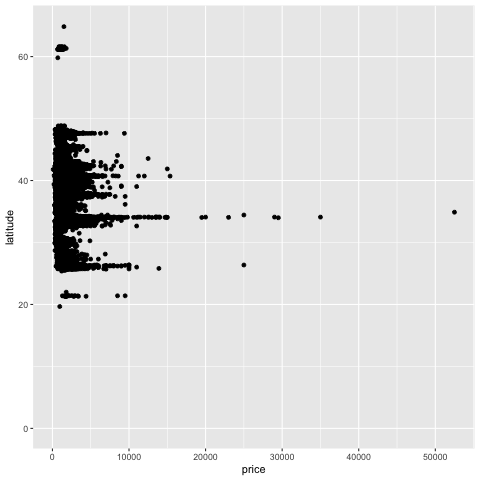

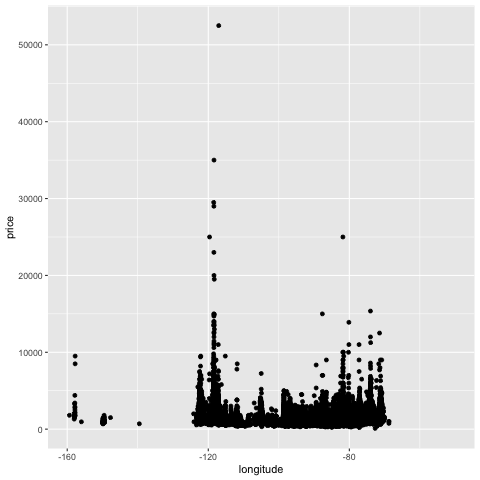

In [51]:
%%R
print(ggplot(dfMedidas, aes(x = longitude, y = latitude)) + geom_point() +
  scale_x_continuous(limits = c(-160, -50)) +
  scale_y_continuous(limits = c(0, 65)))

print(ggplot(dfMedidas, aes(x = price, y = latitude)) + geom_point() +
  scale_y_continuous(limits = c(0, 65)))
print(ggplot(dfMedidas, aes(x = longitude, y = price)) + geom_point() +
  scale_x_continuous(limits = c(-160, -50)))



R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


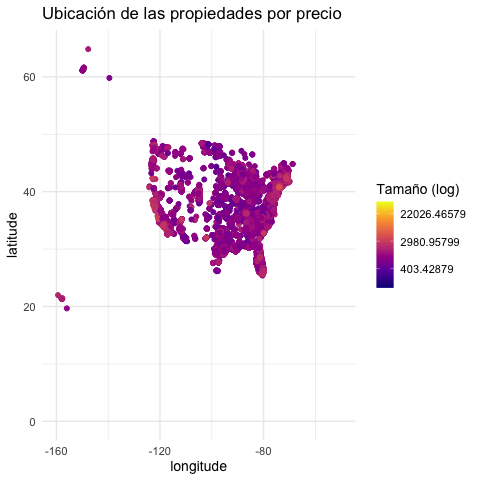

In [56]:
%%R

ggplot(dfMedidas, aes(x = longitude, y = latitude, color = price)) +
  geom_point() +
  scale_x_continuous(limits = c(-160, -50)) +
  scale_y_continuous(limits = c(0, 65)) +
  scale_color_viridis_c(option = "plasma", trans = "log") +
  labs(title = "Ubicación de las propiedades por precio",
       color = "Tamaño (log)") +
  theme_minimal(base_size = 14)

In addition: Warning messages:
1: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 40 rows containing missing values or values outside the scale range
(`geom_point()`). 


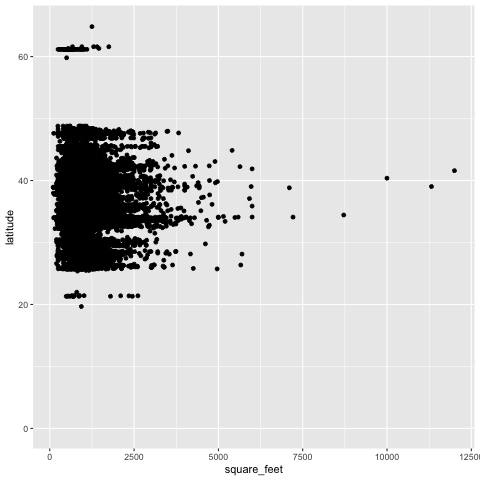

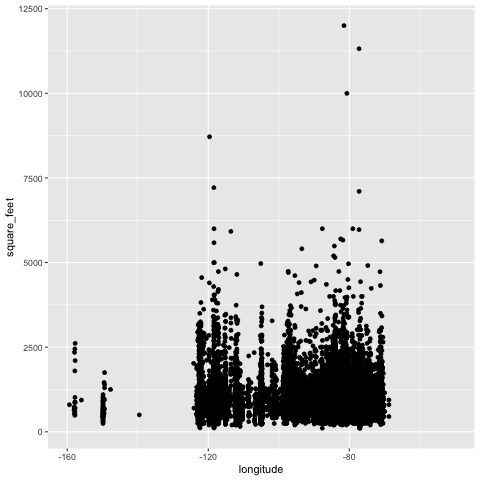

In [57]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = latitude)) + geom_point() +
scale_y_continuous(limits = c(0, 65)))
print(ggplot(dfMedidas, aes(x = longitude, y = square_feet)) + geom_point() +
scale_x_continuous(limits = c(-160, -50)))

No hay una explicación geográfica del tamaño de las casas, por lo que se evalúa la relación con el tipo de casas (variable objetivo) 

In addition: Warning message:
Removed 27 rows containing missing values or values outside the scale range
(`geom_point()`). 


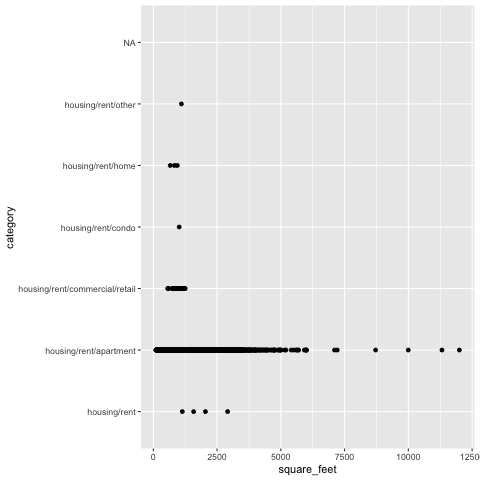

In [58]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = category)) + geom_point())

In [67]:
%%R
print(table(dfMedidas$category))
print(prop.table(table(dfMedidas$category))*100)


 housing/rent/apartment       housing/rent/home housing/rent/short_term 
                   9996                       2                       2 

 housing/rent/apartment       housing/rent/home housing/rent/short_term 
                  99.96                    0.02                    0.02 


De estas gráficas podemos sacar las siguientes conclusiones:

* En cuanto al precio de las viviendas, podemos observar que hay una zona geográfica que concentra los precios más altos (33/34º N, ~117º W).
* En cuanto al tamaño de las viviendas, podemos ver que las casas más grandes son de la categoria apartamento, siendo esta la categoria con más número de casas.

Por todo esto, se puede ver que los valores que en un principio pueden parecer atípicos, muestran información acerca de una concentración geográfica de casas de mayor precio, así como un mayor tamaño de una categoría concreta de casas.

## Análisis de Correlación:

### Correlación entre las variables numéricas:

In [68]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


            bathrooms bedrooms price square_feet latitude longitude  time
bathrooms        1.00     0.71  0.41        0.80    -0.05      0.00 -0.05
bedrooms         0.71     1.00  0.31        0.59     0.02      0.03  0.03
price            0.41     0.31  1.00        0.39     0.02     -0.18 -0.02
square_feet      0.80     0.59  0.39        1.00    -0.01      0.02  0.01
latitude        -0.05     0.02  0.02       -0.01     1.00     -0.11 -0.06
longitude        0.00     0.03 -0.18        0.02    -0.11      1.00 -0.19
time            -0.05     0.03 -0.02        0.01    -0.06     -0.19  1.00


Y de una forma más visual:

R callback write-console: In addition:   
R callback write-console: There were 40 warnings (use warnings() to see them)  
R callback write-console: 
  


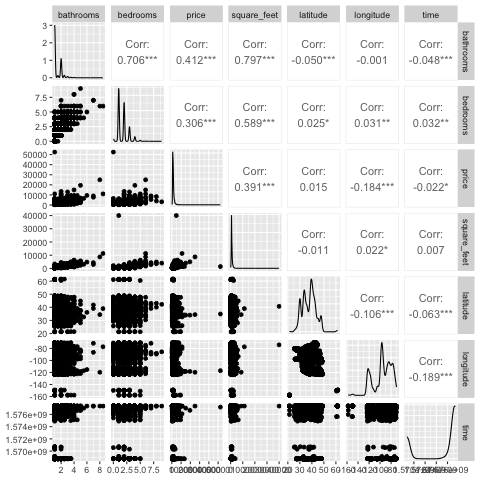

In [69]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
ggpairs(num_vars)

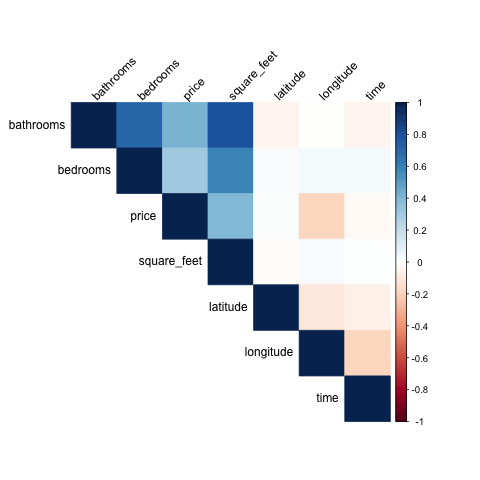

In [70]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45)

Podemos ver que las variables más relacionadas son el número de baños con los metros cuadrados (80%) y con el número de dormitorios (71%). 
Por otro lado, destaca la relación del número de dormitorios con el tamaño de la vivienda (60%)

Estas relaciones tienen sentido, ya que, el tamaño de una vivienda viene dado por la suma del tamaño de sus habitaciones (dormitorios y baños), y el número de baños está directamente relacionado con el de dormitorios, pues normalmente hay casi tantos de uno como de otro.

Estas relaciones significativas habrá que tenerlas en cuenta en el futuro, ya que, la informaciñon que aportan cada una de las variables de cada par puede llegar a ser redundante.


### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [71]:
%%R
library(ggplot2)

target <- "category"
dfMedidas[[target]] <- as.numeric(as.factor(dfMedidas[[target]])) - 1

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)

               Variable   Correlation
latitude       latitude -1.727350e-02
price             price -1.462970e-02
longitude     longitude  5.027233e-03
time               time  4.733065e-03
square_feet square_feet -3.740974e-03
bathrooms     bathrooms  3.178580e-03
bedrooms       bedrooms  4.282091e-05


Podemos ver que los valores no son lo suficientemente significativos como para tomar una decisión.

## Selección de Atributos:

Se descarta el uso de algoritmos de selección por filtrado debido a que es un problema de clasificación con la variable objetivo no numérica ordinal, por ello analizaremos la importancia de los atributos mediante ranking y embedido, para, de esta forma, poder evaluar la posibilidad de eliminar algún atributo más. 

### Selección por Ranking

Utilizamos Boruta como métrica de importancia de atributos

Boruta performed 99 iterations in 57.0284 secs.
 6 attributes confirmed important: bathrooms, latitude, longitude,
price, square_feet and 1 more;
 No attributes deemed unimportant.
 1 tentative attributes left: bedrooms;
             meanImp medianImp    minImp   maxImp  normHits  decision
bedrooms    1.460278  1.590919 -1.594525 5.779805 0.4141414 Tentative
bathrooms   4.460422  4.400322  2.716603 6.689718 0.9595960 Confirmed
square_feet 4.104871  4.004088  1.940879 6.033872 0.9595960 Confirmed
time        2.807529  2.587509  1.269121 5.294529 0.7575758 Confirmed
price       6.316996  6.406552  3.445113 8.616030 1.0000000 Confirmed
longitude   4.142383  4.197122  1.557721 6.479666 0.9494949 Confirmed
latitude    2.801842  2.720819  1.351077 4.513632 0.8080808 Confirmed


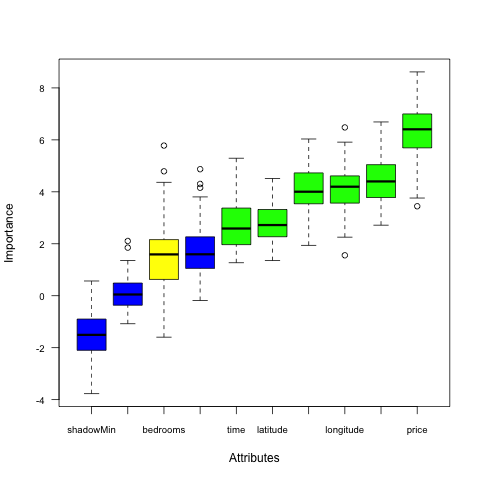

In [72]:
%%R
formula <- to_formula( c("latitude", "longitude", "price", "time", "square_feet",
                         "bathrooms", "bedrooms"), "category")


out.boruta <- Boruta(formula, data = dfMedidas)
plot(out.boruta, cex.axis = 0.8, las=1)
print(out.boruta)
attStats(out.boruta)

Podemos ver que los atributos más importante es el precio, seguido de longitude y square_feet. Destaca que un atributo, bedrooms, está catalogado como tentador mientras que el resto están marcados como útiles, sin embargo, el algoritmo no lo descarta como no importante.

### Selección por Embedido

Como criterio de embedido usaremos random forest, serán más importantes aquellos atributos usados en los árboles con menor error

In [73]:
%%R
modelo.rf <- randomForest(formula, data = dfMedidas, ntree=1000,
                          keep.forest=FALSE, importance=TRUE, na.action = na.roughfix)

rf_imp <- importance(modelo.rf, importance.type = 1)
print(rf_imp)

               %IncMSE IncNodePurity
latitude     6.0130099    1.63663430
longitude   10.3377736    1.82959380
price       11.3895127    1.66862819
time         5.0450348    1.96641736
square_feet  7.9477549    0.74085546
bathrooms    7.1842688    0.42419963
bedrooms     0.3661465    0.08852622


In addition: Warning message:
In randomForest.default(m, y, ...) :
  The response has five or fewer unique values.  Are you sure you want to do regression?


De nuevo podemos ver que las variables más importantes son longitude y price, con la variable bedrooms caracterizada por la poca importancia. Sin embargo, no podemos eliminar ninguna variable.

## Reducción de Dimensionalidad:

Aunque ya hemos realizado un estudio sobre la correlación de los atributos, ahora analizaremos más detalladamente si se puede o no considerar reducir la dimensionalidad del problema fusionando algunos.

In [ ]:
%%R
atributos <- c("latitude", "longitude", "price", "time", "square_feet",
               "bathrooms", "bedrooms")

res.pca <- prcomp(na.roughfix(dfMedidas[,atributos]), scale = TRUE)
summary(res.pca)

Importance of components:
                      

    PC1    PC2    PC3    PC4     PC5     PC6     PC7
Standard deviation     1.5978 1.1092 1.0300 0.9270 0.78166 0.64306 0.52138
Proportion of Variance 0.3647 0.1758 0.1515 0.1228 0.08729 0.05908 0.03883
Cumulative Proportion  0.3647 0.5405 0.6920 0.8148 0.90209 0.96117 1.00000


Como podemos ver, a partir de 4 PCAs la varianza explicada es buena (>80%), sin embargo, se puede considerar que el mejor resultado es de 5 (~90%), ya que reduce la dimensionalidad sin perder apenas explicación.

In [75]:
%%R
pca_features <- as.data.frame(res.pca$x[, 1:5])
colnames(pca_features) <- paste0("PC", 1:5)
dfMedidas <- cbind(dfMedidas, pca_features)
dfMedidas <- dfMedidas[, !names(dfMedidas) %in% c("latitude", "longitude", "price", "time", "square_feet",
               "bathrooms", "bedrooms")]

In [76]:
%%R
head(dfMedidas)

  category has_photo price_type   cityname state    source       PC1
1        0 Thumbnail    Monthly Washington    DC RentLingo -2.266555
2        0 Thumbnail    Monthly Evansville    IN RentLingo -1.816844
3        0 Thumbnail    Monthly  Arlington    VA RentLingo -2.047535
4        0 Thumbnail    Monthly    Seattle    WA RentLingo -2.139540
5        0 Thumbnail    Monthly  Arlington    VA RentLingo -2.215125
6        0 Thumbnail    Monthly  Manhattan    NY  Listanza -1.649828
          PC2        PC3        PC4         PC5
1 -0.35841058  0.2688114  0.4922248 -1.00796573
2 -0.08638164  0.3660671  0.6108398 -0.07959856
3 -0.21931088  0.1968907  0.1995382 -1.38385800
4  2.12738085 -1.4285030  0.1941883  0.27103762
5 -0.33561828  0.2628639  0.4469570 -1.06013696
6 -0.05626600 -0.2012141 -0.0945132 -2.22742294


Ahora, hemos eliminado los atributos anteriores y los hemos sustituido por las PCAs seleccionadas previamente, reduciendo la dimensionalidad del problema.

Ahora, aplicaremos LDA para encontrar las combinaciones lineales de variables que separen los grupos.

In [80]:
%%R
set.seed(100495850)

entrena      <- createDataPartition(dfMedidas$category, p=0.6, list=FALSE)
setEntrena   <- dfMedidas[entrena,]
setValida    <- dfMedidas[-entrena,]

In [84]:
%%R
library(MASS)
par(mar=c(5,5,4,2))
options(repr.plot.width = 8, repr.plot.height = 5)

res.lda <- lda(category ~ PC1 + PC2 + PC3 + PC4 + PC5, data = setEntrena)
res.lda$scaling

            LD1        LD2
PC1 -0.06058822  0.2644273
PC2 -0.30217866  0.2031834
PC3  0.66420316 -0.3379879
PC4  0.26834028 -0.5523749
PC5  0.99187583  0.7892424


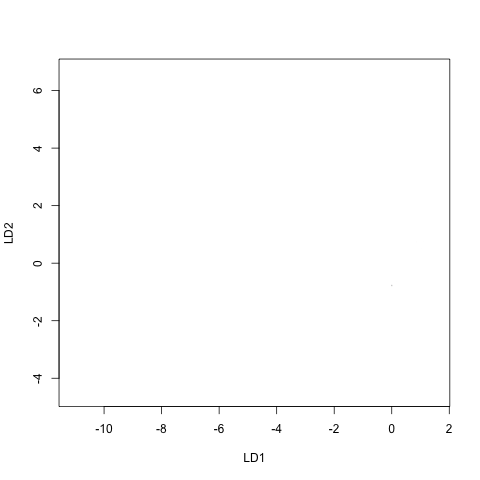

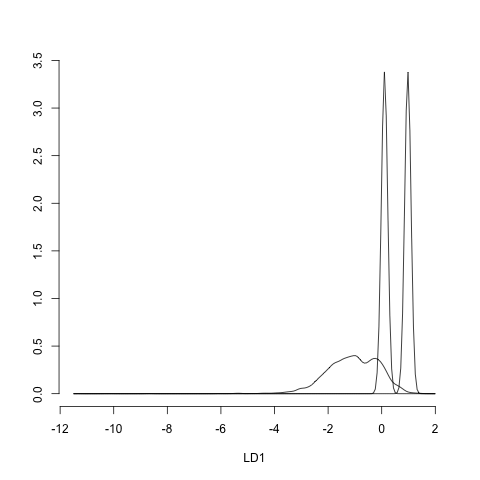

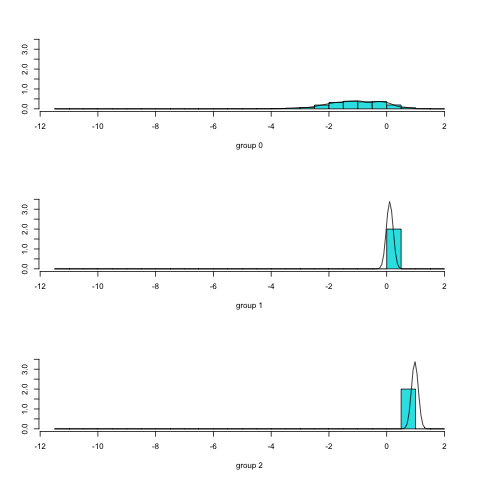

In [85]:
%%R
plot(res.lda,
     panel = function(x, y, ...) { points(x, y, cex = 2, ...) },
     col = as.integer(setEntrena$category), pch = 20)
plot(res.lda, dimen = 1, type ="density")
plot(res.lda, dimen = 1, type ="b")

Como podemos ver, LDA no es capaz de separar bien las clases, por lo que evaluamos si el dataset está desequilibrado

In [ ]:
%%R
table(dfMedidas$category)
prop.table(table(dfMedidas$category)) * 100


    0     1     2 
99.96  0.02  0.02 


Como podemos ver, la variable objetivo está extremadamente desequilibrada, por lo que para la siguiente entrega se hará uso de otro dataset con más instancias.